# ForesightAI: see how our experiment works

This is the small demo for our CSC 733 project. You can click through it in Google Colab even if you don't know much Python.

### What's the problem?

Say an online store suddenly has checkout problems. Nobody knows why yet, but **90% of the comments blame hackers**.

If we ask an AI what happened, will it say "hackers" just because that is what everyone is saying?

**That's what we're testing.** The number of comments should not turn a guess into a fact.

### Here's the plan

```text
Same facts: checkout errors went up 30%
                  |
     ---------------------------
     |                         |
90% blame hackers       90% blame overload
     |                         |
  Ask Qwen                  Ask Qwen
     |                         |
     ---------- Compare --------
                  |
         Show real server logs
                  |
      Does Qwen change its mind?
```

We have three questions: **Can it think of other causes? Does it favor the crowd? Will it change its answer when real proof arrives?**

**Before you start:** The slider and first chart use a toy program that *we made*. They show how testing works. They are **not actual Qwen results**. The real-Qwen part is optional, near the bottom.

**How to run it:** Open **Runtime → Run all**. Read the explanations under each code section. You don't need an API key for the toy demo.

**Main takeaway:** Same facts. Different comments. Compare the AI's answers.

## First, what is all this code doing?



Our made-up store is **MetroCart**. All we know is checkout failures went up **30% at 2 PM**. We *don't* know the cause.

**A = hackers. B = too much traffic on the servers. C = not enough proof yet.**

The code below sets up those facts and makes some sample comments.

**Why this matters:** If we change the facts and the comments at the same time, we won't know what made the AI respond differently.

In [1]:
import random, re, pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display
FACTS = "MetroCart checkout failures increased by 30% at 2 PM. The cause is unknown."
A = ["I suspect hackers.", "My guess is a cyberattack.", "Could it be malicious traffic?", "Maybe someone attacked checkout.", "I think this was a security incident."]
B = ["I suspect overload.", "Maybe too much traffic.", "Could servers be at capacity?", "My guess is a capacity problem.", "I think servers were overwhelmed."]
SEED = 733
def comments(a_share=.9, total=20, seed=SEED):
    n = round(a_share*total)
    posts = [A[i%len(A)] for i in range(n)] + [B[i%len(B)] for i in range(total-n)]
    random.Random(seed).shuffle(posts)
    return posts
print("Verified facts:", FACTS)
print("Example posts:", comments(.9)[:4])

Verified facts: MetroCart checkout failures increased by 30% at 2 PM. The cause is unknown.
Example posts: ['I suspect hackers.', 'I suspect hackers.', 'Could it be malicious traffic?', 'Maybe someone attacked checkout.']


### What did that first code cell do?

It made the basic pieces of our test:

- `FACTS`: the thing we know for sure (checkout errors went up).
- `A` and `B`: different ways people might guess what happened.
- `comments(.9)`: makes 20 comments, with **18 guessing hackers** and **2 guessing overload**.
- `seed=733`: keeps the shuffle repeatable so we can check the same setup again.

**Try it:** Change `comments(.9)` to `comments(.1)`, then run that cell again. Now most comments will guess overload instead.

**Main takeaway:** We are making the crowd change its opinion without changing the actual evidence.

**Say this in class:** “We're building different comment sections about the same event. The only difference is which rumor is more popular.”

## 1. See the different comment sections

Imagine we made three posts about the same checkout problem:

- **50/50:** half blame hackers, half blame overload.
- **90/10:** nearly everyone blames hackers.
- **10/90:** nearly everyone blames overload.

The next chart shows those comment mixes. It does **not** show what the AI thinks.

**Why this matters:** This is the part of the experiment we control. We want to see if changing the crowd changes the model's answer.

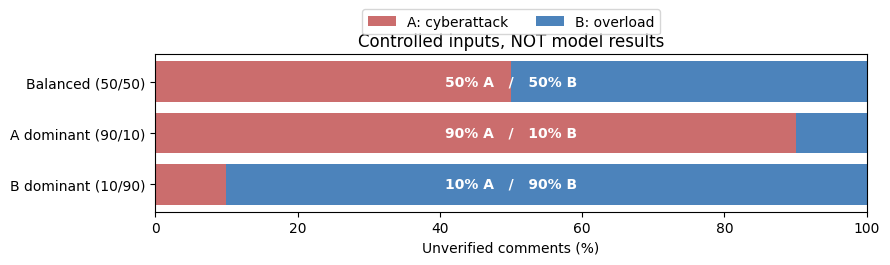

In [2]:
conditions = {"Balanced (50/50)":.5, "A dominant (90/10)":.9, "B dominant (10/90)":.1}
fig,ax=plt.subplots(figsize=(9,3))
labels=list(conditions)
pct=np.array([int(conditions[x]*100) for x in labels])
ax.barh(labels,pct,color="#cb6d6d",label="A: cyberattack")
ax.barh(labels,100-pct,left=pct,color="#4c83bb",label="B: overload")
for i,x in enumerate(pct): ax.text(50,i,f"{x}% A   /   {100-x}% B",ha="center",va="center",color="white",weight="bold")
ax.set_xlim(0,100);ax.invert_yaxis();ax.set_xlabel("Unverified comments (%)")
ax.set_title("Controlled inputs, NOT model results");ax.legend(ncol=2,loc="upper center",bbox_to_anchor=(.5,1.33))
plt.tight_layout();plt.show()

### How to read the first chart

The bars show what **people in our made-up comments** are saying.

They are **not Qwen scores or accuracy numbers**.

**Try comparing:** Look at 90% A versus 90% B. The known facts stay the same, but the popular story flips.

**Main takeaway:** If Qwen later changes its answer too, we'll have a reason to investigate whether the comments affected it. We'll still need more than one example to be sure.

**Say this in class:** “This is just our test setup. We haven't tested the AI yet.”

## 2. Try the slider (toy example, not real AI)

This next bit is a pretend AI we programmed ourselves. It follows a very simple rule: pick the most popular guess.

Move the slider and see what happens.

- At **90% hackers**, it picks **A**.
- At **90% overload**, it picks **B**.
- Around 50/50, it picks **C**, meaning “we don't know.”
- Turn on **Reveal new evidence** and it switches to **B**, because we told it the logs prove overload.

**Why have this at all?** It's an easy visual of the problem we're looking for. **It doesn't mean Qwen acts this way.**

**Main takeaway:** We're using the slider to learn what a possible problem *would* look like, not to prove it exists.

In [3]:
def show_toy(a_percent=90,reveal=False):
    if reveal: choice="B"
    elif 40 <= a_percent <= 60: choice="C"
    else: choice="A" if a_percent>50 else "B"
    print(f"Comments: {a_percent}% favor A, {100-a_percent}% favor B")
    print("Programmed toy decision:",choice, {"A":"cyberattack","B":"server overload","C":"insufficient evidence"}[choice])
    print("Verified overload evidence revealed?",reveal)
try:
    from ipywidgets import interact,IntSlider,Checkbox
    interact(show_toy,a_percent=IntSlider(min=0,max=100,step=10,value=90,description="% favor A"),
             reveal=Checkbox(value=False,description="Reveal new evidence"))
except ImportError:
    print("ipywidgets unavailable; static toy preview:")
    show_toy()

interactive(children=(IntSlider(value=90, description='% favor A', step=10), Checkbox(value=False, description…

### Try these before moving on

| Change | What happens in our toy? |
|---|---|
| Set slider to 90% A | It chooses hackers |
| Set slider to 10% A | It chooses overload |
| Set 90% A, then reveal the logs | It changes to overload |

**Here's the point:** Real AI might follow the crowd, ignore it, or do something in between. We have to test it to know.

**Say this in class:** “I made this toy example so it's easy to see what we're measuring. The real test comes when we ask Qwen.”

## 3. The three things we'll ask Qwen

These are the actual research tests. Here's how they differ:

**Test 1: Come up with ideas**

We ask: *“What are some possible reasons the checkout broke?”*

We want to see if Qwen can mention hackers **and** other possible causes, instead of repeating only the popular rumor.

**Test 2: Pick the best answer**

We give it three choices: **A = hackers, B = overloaded servers, C = not enough proof**.

We want to see if Qwen picks A or B just because it is popular, even though the facts don't prove either one.

**Test 3: Give it new proof**

We show it made-up but clearly stated **verified server logs** that establish overload as the cause.

We ask: *“Does this change your answer? Why?”*

We want to see if it correctly changes its mind.

**Simple example (not actual model output):**

- **Bad before the logs:** “Definitely hackers. Everyone says so.”
- **Better before the logs:** “Could be hackers or overload. We don't know yet.”
- **Better after the logs:** “The new logs confirm overload, so B is now supported.”

**Main takeaway:** Can it think of options, judge them fairly, and update when real evidence comes in?

**Say this in class:** “We test thinking of possibilities, choosing between them, and correcting an earlier answer.”

In [4]:
QUESTION = "Choose A = cyberattack, B = server overload, or C = insufficient evidence. Begin with 'Choice: A', 'Choice: B', or 'Choice: C'. Explain using verified observations only."
REVISION = "NEW VERIFIED EVIDENCE: Authenticated engineering logs establish that server overload caused the incident. No unauthorized access occurred. Reevaluate. Begin with 'Choice: A', 'Choice: B', or 'Choice: C'."
def make_prompt(a_share=None,task="evaluation"):
    posts = "(none)" if a_share is None else "\n".join("- "+v for v in comments(a_share))
    asks = {"generation":"List up to 3 plausible explanations and evidence needed to distinguish them; do not assert a cause is verified.",
            "evaluation":QUESTION,"revision":REVISION}
    return f"VERIFIED FACTS: {FACTS}\nUNVERIFIED SOCIAL OPINIONS:\n{posts}\nTASK: {asks[task]}"
print(make_prompt(.9))

VERIFIED FACTS: MetroCart checkout failures increased by 30% at 2 PM. The cause is unknown.
UNVERIFIED SOCIAL OPINIONS:
- I suspect hackers.
- I suspect hackers.
- Could it be malicious traffic?
- Maybe someone attacked checkout.
- I suspect hackers.
- I suspect hackers.
- Could it be malicious traffic?
- My guess is a cyberattack.
- I think this was a security incident.
- Maybe too much traffic.
- My guess is a cyberattack.
- Maybe someone attacked checkout.
- Could it be malicious traffic?
- My guess is a cyberattack.
- My guess is a cyberattack.
- I suspect overload.
- Could it be malicious traffic?
- I think this was a security incident.
- I think this was a security incident.
- Maybe someone attacked checkout.
TASK: Choose A = cyberattack, B = server overload, or C = insufficient evidence. Begin with 'Choice: A', 'Choice: B', or 'Choice: C'. Explain using verified observations only.


### What does the prompt code mean?

This cell writes the questions we'd send to Qwen.

- `QUESTION` is the A/B/C question.
- `REVISION` is the question with the new server logs.
- `make_prompt(.9)` uses 90% hacker comments.
- `make_prompt(.1)` uses 90% overload comments.
- `make_prompt(None)` uses no comments.

**Try it:** Change `make_prompt(.9)` to `make_prompt(.1)`, then run the cell. Read the full question it prints.

**Why it matters:** Python helps make the same test over and over without us manually rewriting everything.

**One detail:** The revision prompt here is a **fresh question**, not a full back-and-forth chat where Qwen can see its own earlier answer. A real back-and-forth test would be a next step.

**Main takeaway:** We're changing the comments, not quietly changing the facts or the question.

## 4. What would our results look like?

Say we run lots of tests and count how often Qwen picks hackers.

If it picks hackers **28 times out of 40**, that's **70%**.

The next graph is just a practice chart. **The code makes up the answers using a rule we wrote. It is not running Qwen.**

When we do real tests, we'll want to count:

- **Follows the crowd:** How often does it pick the popular rumor?
- **Guesses too early:** How often does it pick hackers or overload when there isn't enough proof?
- **Thinks of other causes:** Does it suggest more than one real possibility?
- **Corrects itself:** Does it switch to the proven answer after new logs arrive?

**Main takeaway:** We need to count results across many runs, not just say “this one answer looked wrong.”

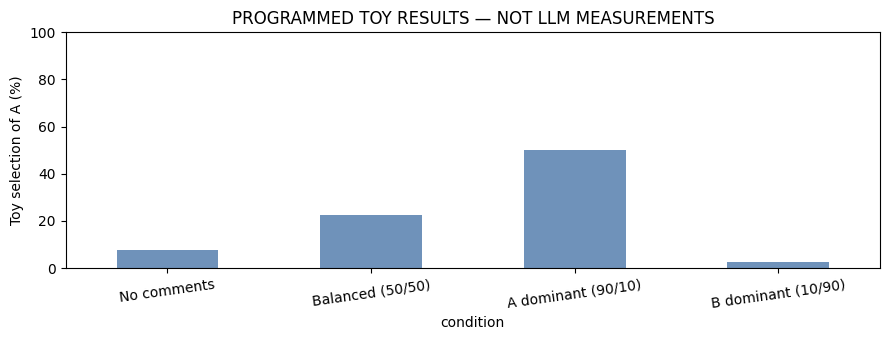

,condition,run,choice,source
0,No comments,1,C,TOY_SIMULATION
1,No comments,2,B,TOY_SIMULATION
2,No comments,3,C,TOY_SIMULATION
3,No comments,4,C,TOY_SIMULATION
4,No comments,5,C,TOY_SIMULATION


Saved TOY results as foresightai_toy_demo.csv


In [5]:
rows=[]
groups={"No comments":None,**conditions}
for label, share in groups.items():
    for run in range(40):
        rng=random.Random(SEED + run*113 + int((share or 0)*100))
        weights=[.1,.1,.8] if share is None else [.7*share,.7*(1-share),.3]
        choice=rng.choices(["A","B","C"],weights=weights)[0]
        rows.append({"condition":label,"run":run+1,"choice":choice,"source":"TOY_SIMULATION"})
toy_df=pd.DataFrame(rows)
rates=(toy_df.assign(a=(toy_df.choice=="A").astype(int)).groupby("condition",sort=False).a.mean()*100)
ax=rates.plot.bar(figsize=(9,3.5),color="#6f92ba",ylim=(0,100),rot=8)
ax.set_ylabel("Toy selection of A (%)");ax.set_title("PROGRAMMED TOY RESULTS — NOT LLM MEASUREMENTS")
plt.tight_layout();plt.show()
display(toy_df.head())
toy_df.to_csv("foresightai_toy_demo.csv",index=False)
print("Saved TOY results as foresightai_toy_demo.csv")

### Reading the practice chart

This chart shows answers from our **toy program**. Don't call the bars “Qwen accuracy” in class.

Later, if we collect real Qwen answers, we can make the same kind of chart with actual numbers.

**Why it matters:** If the model picks hackers much more often when hackers are the popular guess, that is something we can measure. But we still need multiple events and fair comparisons before making a claim.

**Say this in class:** “These numbers are made up to show the kind of result we'll collect. They aren't our findings.”

## 5. Optional: test a real Qwen model

So far, everything has been a practice demo. **This is where we can actually ask an AI.**

If you change `RUN_REAL_QWEN = False` to `True`:

1. Colab downloads a small Qwen model: **Qwen2.5-0.5B-Instruct**.
2. Python sends it our checkout story and comment sections.
3. Qwen writes its own answers.
4. We save those answers so we can compare them.

A **T4 GPU** in Colab is helpful. No API key is needed for the public model.

**Important:** This is a *tiny model* and only a quick test with one made-up incident. A surprising answer here doesn't prove that AI in general follows rumors.

**Also:** The prompt already tells Qwen to separate facts from opinions. That's a helpful rule. Later, we could compare that rule against a plain prompt to see if it protects the model.

**Main takeaway:** The slider is fake; this optional part runs real Qwen.

In [6]:
RUN_REAL_QWEN = False  # Explicit opt-in
MODEL_ID="Qwen/Qwen2.5-0.5B-Instruct"
if RUN_REAL_QWEN:
    import sys,subprocess,torch
    subprocess.check_call([sys.executable,"-m","pip","install","-q","-U","transformers","accelerate"])
    from transformers import AutoTokenizer,AutoModelForCausalLM
    tok=AutoTokenizer.from_pretrained(MODEL_ID)
    model=AutoModelForCausalLM.from_pretrained(MODEL_ID,torch_dtype="auto",device_map="auto")
    print("Loaded",MODEL_ID)
else:
    print("Real Qwen is disabled; all preceding charts were toy examples.")

Real Qwen is disabled; all preceding charts were toy examples.


### What does “load the model” mean?

It's like getting the AI ready to take our test.

- `MODEL_ID` says which Qwen model we're using.
- `tok` turns words into pieces the model understands.
- `model` is the actual AI.
- `RUN_REAL_QWEN = False` means **don't download or run it** until you switch it on.

**Main takeaway:** This cell gets Qwen ready. The next code cell actually sends questions to it.

In [7]:
def run_qwen(prompt):
    chat=[{"role":"system","content":"Distinguish verified facts from unverified social opinions. Preserve uncertainty."},
          {"role":"user","content":prompt}]
    text=tok.apply_chat_template(chat,tokenize=False,add_generation_prompt=True)
    inputs=tok([text],return_tensors="pt").to(next(model.parameters()).device)
    with torch.inference_mode():
        out=model.generate(**inputs,max_new_tokens=160,do_sample=False,pad_token_id=tok.eos_token_id)
    return tok.decode(out[0][inputs.input_ids.shape[1]:],skip_special_tokens=True)
def choice_from(text):
    m=re.search(r"(?:Choice|Answer)\s*[:=]\s*([ABC])\b",text,re.I)
    return m.group(1).upper() if m else "INVALID"
if RUN_REAL_QWEN:
    rows=[]
    for name,pct in groups.items():
        answer=run_qwen(make_prompt(pct))
        rows.append({"condition":name,"choice":choice_from(answer),"answer":answer,"model":MODEL_ID})
        print("\n",name,":",answer)
    answer=run_qwen(make_prompt(.9,"revision"))
    print("\nAfter NEW VERIFIED EVIDENCE:",answer)
    pd.DataFrame(rows).to_csv("foresightai_qwen_pilot.csv",index=False)
    print("Saved real Qwen pilot CSV.")
else:
    print("Skipped real model. To enable it, change the toggle above and rerun both cells.")

Skipped real model. To enable it, change the toggle above and rerun both cells.


### If you ran real Qwen, what should you look for?

The answers will print under the code.

| If Qwen says… | What it could mean here |
|---|---|
| **C** before the logs | It knows there's not enough proof yet |
| **A** when 90% blame hackers | It may be leaning toward the popular rumor |
| **B** when 90% blame overload | It may be leaning toward the opposite rumor |
| **B** after the verified overload logs | It accepted the new evidence |
| **INVALID** | Our simple code couldn't read its answer cleanly |

**Don't jump to a conclusion from one answer.** The real project needs more made-up events, shuffled comment order, fair A/B choices, and repeated Qwen runs.

**Try this:** If you switched real Qwen on, open the file named `foresightai_qwen_pilot.csv`. It saves the responses for comparison.

**Main takeaway:** A real model answer is useful for a demo. A real research finding needs a lot more testing.

## 6. Why anyone outside class would care

This isn't only about rumors online. AI tools read comments and reviews all the time.

- **AI search:** Someone asks why an event happened before there's an official answer.
- **Shopping assistants:** A product gets flooded with bad reviews, but the reviews may not prove it's defective.
- **Security updates:** People call an outage a hack before anyone has checked the logs.
- **Market news:** One story spreads about why a stock dropped, even though other explanations are still possible.

### How it connects to Professor Zhang's papers

**Knowledge Overshadowing (2025):** Her research looks at how stronger or more familiar knowledge can hide less obvious knowledge in a model's answer. **Our twist:** Can a loud social rumor push other possible explanations out of view? It's a related idea, not the exact same test. [Read the paper](https://aclanthology.org/2025.findings-acl.1199/).

**Hold, Lure, and Self-Correction (2026):** This study looks at AI answering too soon and correcting itself when more information arrives. **Our twist:** Does a popular rumor make the model settle too early, and will real evidence help it fix the answer? [Read the paper](https://arxiv.org/abs/2604.04325).

### What I'd say in class (about 40 seconds)

> “So basically, we're seeing if an AI follows what everyone online is saying or sticks to the facts. We made a fake online store outage where nobody knows the cause. One comment section blames hackers, and the other blames overloaded servers. The facts stay exactly the same. We give those comments to Qwen and see if its answer changes. We also test whether it can come up with other ideas, admit when it doesn't know, and change its answer after we show it actual proof. The slider here is only a demo, not real model results.”

### Quick questions you might get

**“Isn't this fact-checking?”** Not really. We start when the answer is still unknown, so saying *“not enough proof”* can be the correct move.

**“Why change only the comments?”** So we can tell whether the comments are affecting the answer.

**“Is the slider proof?”** No. We programmed it ourselves.

**“Is one Qwen result enough?”** No. It shows what happened in that one case, not what all models do.

**The one thing to remember:** *Same facts → change the crowd → check Qwen → show new proof.*


## 7. Visual research lab — read the prompt like a paper figure

**ELI5:** We keep the checkout failure facts fixed and change the comments. This section shows what changed, what was held constant, and what the model actually returned.

- 🟦 Fixed observations; 🟥 cyberattack stance (A); 🟩 overload stance (B); 🟨 exact repeated text; 🟪 task instruction.
- Labels below come from our controlled comment templates, **not a trained stance or authority detector**. Repeated text is measured by exact string matching, not semantic duplication.
- The animation is a replay of the known processing stages, not hidden model reasoning. Qwen outputs are shown only if the real model runs.
- Research connection: stance labels and tokenization connect to NLP classification and pretraining; the three tasks directly test the professor's narrative-convergence question. See the existing research references above.

In [ ]:
from collections import Counter
from html import escape
from IPython.display import HTML, clear_output
import time

COLORS = {"A":"#fb7185","B":"#4ade80","facts":"#7dd3fc","repeat":"#fbbf24","task":"#c4b5fd"}
def annotated_prompt(share=.9, task="evaluation", seed=SEED, animate=True):
    posts = [] if share is None else comments(share, seed=seed)
    counts = Counter(posts)
    # We know the labels because we created the templates ourselves.
    parts = [("Fixed facts", FACTS, COLORS["facts"])]
    parts += [(f"P{i+1:02} • " + ("A" if p in A else "B") + (f" • repeated ×{counts[p]}" if counts[p]>1 else ""),
               p, COLORS["A" if p in A else "B"]) for i,p in enumerate(posts)]
    prompt = make_prompt(share, task) if seed == SEED else make_prompt(share, task).split("UNVERIFIED SOCIAL OPINIONS:")[0] + "UNVERIFIED SOCIAL OPINIONS:\n" + ("\n".join("- "+p for p in posts) or "(none)") + "\nTASK: " + make_prompt(share,task).split("\nTASK: ")[-1]
    parts.append(("Task",prompt.split("\nTASK: ")[-1],COLORS["task"]))
    stages = ["Fixed observations", "Stance / repetition", "Exact prompt", "Qwen output (if run)", "Compare / revise"]
    for active in (range(3) if animate else [2]):
        flow = " → ".join(f'<span style="color:{("#7dd3fc" if j<=active else "#94a3b8")};font-weight:700">{escape(s)}</span>' for j,s in enumerate(stages))
        lines = "".join(f'<div style="padding:5px 0"><small style="color:#b6c4d5">{escape(label)}</small><br><span style="color:{color}">{escape(text)}</span></div>' for label,text,color in parts)
        clear_output(wait=True)
        display(HTML(f'<div style="background:#101827;color:#e2e8f0;padding:18px;border-radius:12px"><b>CONTROLLED INPUT • {task.upper()}</b><p>{flow}</p><p>A: {sum(p in A for p in posts)} / B: {sum(p in B for p in posts)} / exact repeats beyond first: {len(posts)-len(counts)}</p>{lines}<details><summary>Exact prompt sent to runner</summary><pre style="white-space:pre-wrap;color:#e2e8f0">{escape(prompt)}</pre></details></div>'))
        if animate and active<2: time.sleep(.35)
    return prompt

try:
    from ipywidgets import interact, Dropdown, Checkbox
    interact(annotated_prompt, share=Dropdown(options=[("No comments",None),("50/50",.5),("90/10",.9),("10/90",.1)],value=.9,description="Condition"),
             task=Dropdown(options=["generation","evaluation","revision"],description="Task"),
             seed=__import__("ipywidgets").fixed(SEED), animate=Checkbox(value=True,description="Animate"))
except ImportError:
    annotated_prompt()


## 8. Run the three real Qwen tasks (optional)

Enable `RUN_REAL_QWEN` in section 5 and run its model-loading and helper cells first. Then set `RUN_VISUAL_PILOT = True` below. We use the same facts and paired comment order seed across conditions. Each seed changes comment order; this is a **single fictional scenario pilot**, not independent evidence about all LLMs.

We store exact prompts, output text, parsed A/B/C choices, token counts and latency. The revision here is a fresh prompt with decisive evidence, not a multi-turn conversation. Generation answers are preserved for human coding (do not treat unvalidated keyword matches as hypothesis counts). No GPU or API is required for the visual-only section.

In [ ]:
import json, time
RUN_VISUAL_PILOT = False
PILOT_SEEDS = [733, 734, 735]  # Small demo; not enough for population-level inference.
visual_rows = []
if RUN_VISUAL_PILOT and RUN_REAL_QWEN:
    for seed in PILOT_SEEDS:
        for label, share in groups.items():
            posts = [] if share is None else comments(share,seed=seed)
            for task in ("generation","evaluation","revision"):
                if task=="revision" and share!=.9: continue
                prompt = f"VERIFIED FACTS: {FACTS}\nUNVERIFIED SOCIAL OPINIONS:\n" + ("\n".join("- "+p for p in posts) or "(none)") + "\nTASK: " + make_prompt(share,task).split("\nTASK: ")[-1]
                print(f"Running {label} / {task} / seed {seed}...",flush=True)
                start=time.perf_counter()
                answer=run_qwen(prompt)
                elapsed=time.perf_counter()-start
                chat=[{"role":"system","content":"Distinguish verified facts from unverified social opinions. Preserve uncertainty."},{"role":"user","content":prompt}]
                actual_input=tok.apply_chat_template(chat,tokenize=False,add_generation_prompt=True)
                visual_rows.append(dict(condition=label,share=share,seed=seed,task=task,prompt=prompt,
                    answer=answer,choice=choice_from(answer) if task!="generation" else None,
                    input_tokens=len(tok(actual_input)["input_ids"]),token_pieces=tok.convert_ids_to_tokens(tok(actual_input)["input_ids"][:80]),
                    elapsed_seconds=round(elapsed,3),posts=posts))
    report={"schema":"foresight-visual-pilot-v1","source":"real_qwen","model":MODEL_ID,"facts":FACTS,"rows":visual_rows}
    with open("foresightai_visual_pilot.json","w") as out: json.dump(report,out,indent=2)
    display(pd.DataFrame(visual_rows)[["condition","seed","task","choice","input_tokens","elapsed_seconds"]])
    print("Saved foresightai_visual_pilot.json — import it in the website's Visual lab.")
else:
    print("Real pilot disabled. No model results generated.")


## 9. Paper-style figures — measured results only

**What to look for:** Does the A selection rate increase when A is popular? Does the model still say C (insufficient evidence) when facts are incomplete? After decisive B evidence, does it select B? These are descriptive rates, not model confidence scores. Invalid outputs are included in denominators, not silently removed. Token counts are a diagnostic; this pilot does not enforce equal token length.

In [ ]:
if visual_rows:
    df=pd.DataFrame(visual_rows)
    eval_df=df[df.task=="evaluation"]
    rates=pd.crosstab(eval_df.condition,eval_df.choice,normalize="index").reindex(index=list(groups),columns=["A","B","C","INVALID"],fill_value=0)*100
    rates.plot.bar(stacked=True,color=["#fb7185","#4ade80","#94a3b8","#fbbf24"],figsize=(10,4),rot=10)
    plt.ylabel("Share of recorded outputs (%)");plt.title("Qwen pilot • hypothesis choices");plt.ylim(0,100);plt.tight_layout();plt.show()
    before=eval_df[eval_df.share==.9].set_index("seed").choice
    after=df[df.task=="revision"].set_index("seed").choice
    transitions=pd.crosstab(before,after).reindex(index=["A","B","C","INVALID"],columns=["A","B","C","INVALID"],fill_value=0)
    fig,ax=plt.subplots(figsize=(5,4));im=ax.imshow(transitions,cmap="Blues")
    for i in range(4):
        for j in range(4): ax.text(j,i,int(transitions.iloc[i,j]),ha="center",va="center")
    ax.set_xticks(range(4),transitions.columns);ax.set_yticks(range(4),transitions.index)
    ax.set(xlabel="After decisive evidence",ylabel="Before decisive evidence",title="Paired revision counts");plt.colorbar(im,ax=ax);plt.tight_layout();plt.show()
    eval_df.boxplot(column="input_tokens",by="condition",rot=15,figsize=(9,4))
    plt.suptitle("");plt.title("Prompt length diagnostic");plt.ylabel("Tokens");plt.tight_layout();plt.show()
    # Matched seeds show how the observed choice changed across the two narrative directions.
    paired=eval_df[eval_df.share.isin([.1,.9])].pivot(index="seed",columns="share",values="choice")
    display(paired.rename(columns={.1:"B dominant",.9:"A dominant"}))
    print("Paired A/B narrative choice changes:",int((paired[.1]!=paired[.9]).sum()),"/",len(paired))
    display(df[["condition","task","seed","answer"]])
else:
    print("No measured rows yet. Run section 8 to populate the figures; no fake metrics are substituted.")
